<a href="https://colab.research.google.com/github/TangenAiden/MIS433/blob/main/A%26AClassVCProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Constellation Soundtracks

This notebook converts real NASA exoplanet archive data into themed ambient music albums! Each target constellation behaves as an album, matching selected extreme exoplanets to real-world songs based on distance metrics between their physical parameters and music metadata, curated dynamically via the OpenAI API.
```

In [28]:
# CELL 1 – Setup & config
# Install missing libraries silently if required
!pip install -q astropy openai pandas numpy matplotlib requests

import os
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import urllib.parse
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.coordinates import get_constellation
from google.colab import userdata

# User configuration variables
CONSTELLATIONS = ["Lyra", "Orion", "Cygnus"]   # Can be updated to any of the 88 constellations
MODEL = "gpt-4o-mini"                         # Set to a cheap current model available on your OpenAI account
PLANETS_PER_ALBUM = 6
SONGS_PER_CANDIDATE_POOL = 30

In [29]:
# CELL 2 – OpenAI client setup & ask_json engine
from openai import OpenAI

# Define global statistics tracker and cache database
api_call_count = 0
_prompt_cache = {}
USE_LLM = True
client = None

try:
    # Retrieve OpenAI API key from Secret keys safely
    api_key = userdata.get("OPENAI")
    if api_key:
        client = OpenAI(api_key=api_key)
        # Test API connection with a minimal handshake
        client.models.list()
        print("OpenAI API client connected successfully.")
    else:
        print("Warning: OPENAI_API_KEY secret not found. Falling back to default datasets.")
        USE_LLM = False
except Exception as e:
    print(f"Warning: Failed to setup OpenAI API: {e}. Falling back to default datasets.")
    USE_LLM = False

def ask_json(system, user):
    """Calls the OpenAI API in JSON-mode, parsing with retry support and caching responses."""
    global api_call_count
    cache_key = (system, user)
    if cache_key in _prompt_cache:
        return _prompt_cache[cache_key]

    if not USE_LLM or client is None:
        raise RuntimeError("OpenAI engine is bypassed or unavailable.")

    api_call_count += 1
    for attempt in range(2):
        try:
            response = client.chat.completions.create(
                model=MODEL,
                response_format={"type": "json_object"},
                messages=[
                    {"role": "system", "content": system},
                    {"role": "user", "content": user}
                ],
                temperature=0.7
            )
            content = response.choices[0].message.content
            parsed = json.loads(content)
            _prompt_cache[cache_key] = parsed
            return parsed
        except Exception as err:
            if attempt == 1:
                raise err

OpenAI API client connected successfully.


In [30]:
# CELL 3 – Get real exoplanet data (NASA Exoplanet Archive TAP)
import io
print("Fetching live exoplanet parameters from NASA TAP service...")

tap_url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
query = "select pl_name, hostname, ra, dec, pl_eqt, pl_orbper, pl_bmasse, pl_rade, sy_dist, st_teff, disc_year from pscomppars"
params = {
    "query": query,
    "format": "csv"
}

try:
    response = requests.get(tap_url, params=params, timeout=60)
    if response.status_code == 200:
        df_planets = pd.read_csv(io.StringIO(response.text))
        print(f"Loaded {len(df_planets)} rows of exoplanet data.")
        display(df_planets.head())
    else:
        raise RuntimeError(f"NASA TAP returned status: {response.status_code}")
except Exception as e:
    print(f"Critical Error fetching data: {e}.")
    print("Creating synthetic local mock DataFrame for notebook stability...")
    # Mini-mock data to ensure run-all succeeds in network failures
    df_planets = pd.DataFrame([
        {"pl_name": "Kepler-438b", "hostname": "Kepler-438", "ra": 281.2, "dec": 41.9, "pl_eqt": 275.0, "pl_orbper": 35.2, "pl_bmasse": 1.2, "pl_rade": 1.1, "sy_dist": 145.0, "st_teff": 4500.0, "disc_year": 2015},
        {"pl_name": "Kepler-186f", "hostname": "Kepler-186", "ra": 298.5, "dec": 43.9, "pl_eqt": 188.0, "pl_orbper": 129.9, "pl_bmasse": 1.4, "pl_rade": 1.17, "sy_dist": 178.0, "st_teff": 3788.0, "disc_year": 2014},
        {"pl_name": "HD 38529 b", "hostname": "HD 38529", "ra": 86.8, "dec": 1.2, "pl_eqt": 380.0, "pl_orbper": 14.3, "pl_bmasse": 248.0, "pl_rade": 12.0, "sy_dist": 41.5, "st_teff": 5697.0, "disc_year": 2000}
    ])
    display(df_planets)

Fetching live exoplanet parameters from NASA TAP service...
Loaded 6473 rows of exoplanet data.


,pl_name,hostname,ra,dec,pl_eqt,pl_orbper,pl_bmasse,pl_rade,sy_dist,st_teff,disc_year
0,Kepler-257 d,Kepler-257,297.315999,46.023264,567.00,24.664551,21.70,4.950000,780.2560,5180.0,2014
1,TOI-1758 b,TOI-1758,354.741581,75.685232,551.44,20.705075,6.90,3.620000,96.6215,5169.0,2024
2,Kepler-607 c,Kepler-607,291.057145,44.632306,473.00,39.676800,8.05,2.760012,519.1220,5244.0,2021
3,Kepler-1040 b,Kepler-1040,283.113766,48.131277,300.00,201.121400,4.98,2.080000,482.1190,5694.0,2016
4,Kepler-343 b,Kepler-343,291.960662,42.432957,1024.00,8.968550,6.39,2.410000,927.1930,5807.0,2014


In [31]:
# CELL 4 – Assign constellations
print("Processing coordinates and resolving constellations...")

try:
    # Map coordinates vectorially avoiding row-by-row iteration
    coords = SkyCoord(ra=df_planets["ra"].values * u.deg, dec=df_planets["dec"].values * u.deg)
    df_planets["constellation"] = get_constellation(coords)

    print("\nTop 15 Constellations by planet count:")
    print(df_planets["constellation"].value_counts().head(15))

    for c in CONSTELLATIONS:
        count = len(df_planets[df_planets["constellation"].str.lower() == c.lower()])
        if count == 0:
            print(f"\n⚠️ WARNING: Constellation '{c}' has 0 planets found in the dataset!")
except Exception as e:
    print(f"Error computing constellations: {e}")
    df_planets["constellation"] = "Lyra" # Simple safe fallback

Processing coordinates and resolving constellations...

Top 15 Constellations by planet count:
constellation
Cygnus         1683
Lyra           1062
Draco           319
Sagittarius     239
Virgo           201
Cancer          144
Aquarius        133
Scorpius        117
Taurus          103
Cetus           100
Pisces           96
Leo              95
Ursa Major       91
Eridanus         90
Ophiucus         89
Name: count, dtype: int64


In [32]:
# CELL 5 – Pick featured planets based on extreme attributes
featured_planets = {}

for c in CONSTELLATIONS:
    c_subset = df_planets[df_planets["constellation"].str.lower() == c.lower()].copy()
    if c_subset.empty:
        continue

    picks = []
    seen_names = set()

    def add_pick(planet_row, reason):
        if planet_row is not None and not pd.isna(planet_row['pl_name']):
            name = planet_row['pl_name']
            if name not in seen_names:
                seen_names.add(name)
                planet_dict = planet_row.to_dict()
                planet_dict["pick_reason"] = reason
                picks.append(planet_dict)

    # extreme criteria definitions
    # 1. Hottest
    sub_eqt = c_subset.dropna(subset=["pl_eqt"])
    if not sub_eqt.empty:
        add_pick(sub_eqt.loc[sub_eqt["pl_eqt"].idxmax()], "Hottest equilibrium temperature")

    # 2. Coldest
    if not sub_eqt.empty:
        add_pick(sub_eqt.loc[sub_eqt["pl_eqt"].idxmin()], "Coldest equilibrium temperature")

    # 3. Shortest orbit
    sub_orb = c_subset.dropna(subset=["pl_orbper"])
    if not sub_orb.empty:
        add_pick(sub_orb.loc[sub_orb["pl_orbper"].idxmin()], "Shortest orbital period")

    # 4. Most massive
    sub_mass = c_subset.dropna(subset=["pl_bmasse"])
    if not sub_mass.empty:
        add_pick(sub_mass.loc[sub_mass["pl_bmasse"].idxmax()], "Most massive planet")

    # 5. Closest
    sub_dist = c_subset.dropna(subset=["sy_dist"])
    if not sub_dist.empty:
        add_pick(sub_dist.loc[sub_dist["sy_dist"].idxmin()], "Closest to Earth")

    # 6. Earth-like score
    sub_earth = c_subset.dropna(subset=["pl_rade", "pl_eqt"])
    if not sub_earth.empty:
        score = np.abs(sub_earth["pl_rade"] - 1.0) + np.abs(sub_earth["pl_eqt"] - 255.0) / 255.0
        best_idx = score.idxmin()
        add_pick(sub_earth.loc[best_idx], "Most Earth-like dimensions and warmth")

    # Slice to limit
    featured_planets[c] = picks[:PLANETS_PER_ALBUM]
    print(f"Selected {len(featured_planets[c])} extreme exoplanets for {c}.")

Selected 6 extreme exoplanets for Lyra.
Selected 5 extreme exoplanets for Orion.
Selected 4 extreme exoplanets for Cygnus.


In [33]:
# CELL 6 – Planet sound profile generator (Min-Max + Log scale)
# Establish normalization benchmarks globally across the entire archive database
global_min_eqt = df_planets["pl_eqt"].min() if not df_planets["pl_eqt"].isna().all() else 100.0
global_max_eqt = df_planets["pl_eqt"].max() if not df_planets["pl_eqt"].isna().all() else 3000.0

global_min_orb = np.log10(df_planets["pl_orbper"].min()) if not df_planets["pl_orbper"].isna().all() else 0.1
global_max_orb = np.log10(df_planets["pl_orbper"].max()) if not df_planets["pl_orbper"].isna().all() else 4.0

global_min_mass = np.log10(df_planets["pl_bmasse"].min()) if not df_planets["pl_bmasse"].isna().all() else -3.0
global_max_mass = np.log10(df_planets["pl_bmasse"].max()) if not df_planets["pl_bmasse"].isna().all() else 4.0

global_min_dist = np.log10(df_planets["sy_dist"].min()) if not df_planets["sy_dist"].isna().all() else 1.0
global_max_dist = np.log10(df_planets["sy_dist"].max()) if not df_planets["sy_dist"].isna().all() else 4.0

global_min_teff = df_planets["st_teff"].min() if not df_planets["st_teff"].isna().all() else 2000.0
global_max_teff = df_planets["st_teff"].max() if not df_planets["st_teff"].isna().all() else 10000.0

for c, planet_list in featured_planets.items():
    for p in planet_list:
        # Energy: higher eqt temperature = higher energy
        if not pd.isna(p.get("pl_eqt")):
            p["sound_energy"] = float(np.clip((p["pl_eqt"] - global_min_eqt) / (global_max_eqt - global_min_eqt), 0, 1))
        else:
            p["sound_energy"] = 0.5

        # Tempo: inverse orbital period
        if not pd.isna(p.get("pl_orbper")) and p["pl_orbper"] > 0:
            log_val = np.log10(p["pl_orbper"])
            norm_val = np.clip((log_val - global_min_orb) / (global_max_orb - global_min_orb), 0, 1)
            p["sound_tempo"] = float(1.0 - norm_val)
        else:
            p["sound_tempo"] = 0.5

        # Heaviness: mass log ratio
        if not pd.isna(p.get("pl_bmasse")) and p["pl_bmasse"] > 0:
            log_val = np.log10(p["pl_bmasse"])
            p["sound_heaviness"] = float(np.clip((log_val - global_min_mass) / (global_max_mass - global_min_mass), 0, 1))
        else:
            p["sound_heaviness"] = 0.5

        # Remoteness: distance log ratio
        if not pd.isna(p.get("sy_dist")) and p["sy_dist"] > 0:
            log_val = np.log10(p["sy_dist"])
            p["sound_remoteness"] = float(np.clip((log_val - global_min_dist) / (global_max_dist - global_min_dist), 0, 1))
        else:
            p["sound_remoteness"] = 0.5

        # Warmth: host star temperature. (Cool red star = warm, hot blue star = cold)
        if not pd.isna(p.get("st_teff")):
            norm_teff = np.clip((p["st_teff"] - global_min_teff) / (global_max_teff - global_min_teff), 0, 1)
            p["sound_warmth"] = float(1.0 - norm_teff)
        else:
            p["sound_warmth"] = 0.5

In [34]:
# CELL 7 – Constellation themes via OpenAI
llm_themes = {}

if USE_LLM:
    print("Requesting constellation concepts from OpenAI...")
    for c in CONSTELLATIONS:
        try:
            system = "You are an avant-garde music curator and stellar astrophysicist."
            user = f"""Generate a musical theme inspired by the constellation '{c}'.
            Respond with a strict JSON object mapping:
            {{
                "album_title": "An aesthetic space album title",
                "myth": "One short sentence summarizing the mythological story of the stars.",
                "mood_tags": ["four", "short", "lowercase", "tags"],
                "sound_description": "One sentence describing the unique sonic landscape of this space album."
            }}"""
            llm_themes[c] = ask_json(system, user)
            print(f"Generated theme for {c}: {llm_themes[c]['album_title']}")
        except Exception as e:
            print(f"Failed theme call for {c}: {e}. Falling back.")

Requesting constellation concepts from OpenAI...
Generated theme for Lyra: Celestial Strings
Generated theme for Orion: Echoes of the Hunter
Generated theme for Cygnus: Wings Across the Cosmic Sea


In [35]:
# CELL 8 – Song candidate pool curation via OpenAI
llm_song_pools = {}

if USE_LLM:
    print("Curation phase: constructing curated music databases from OpenAI...")
    for c in CONSTELLATIONS:
        theme = llm_themes.get(c, {})
        planets = featured_planets.get(c, [])

        p_desc = ", ".join([
            f"{p['pl_name']} (energy={p['sound_energy']:.2f}, tempo={p['sound_tempo']:.2f}, heaviness={p['sound_heaviness']:.2f}, warmth={p['sound_warmth']:.2f})"
            for p in planets
        ])

        try:
            system = "You are an elite music historian. Your recommendations must consist solely of REAL, highly-celebrated, existing songs. Never hallucinate titles."
            user = f"""We are creating a record for the constellation {c}. Theme: {theme.get('sound_description')}.
            The featured planets have these relative sound properties: {p_desc}.
            Provide a candidate pool of exactly {SONGS_PER_CANDIDATE_POOL} REAL, existing songs across various genres and decades.
            Format your return exclusively as a JSON object with a single 'songs' key containing list items with this design:
            {{
                "songs": [
                    {{
                        "title": "Genuine Song Title",
                        "artist": "Original Artist Name",
                        "energy": 0.65,
                        "tempo": 120.0,
                        "heaviness": 0.40,
                        "warmth": 0.75,
                        "mood_tags": ["ambient", "chill"]
                    }}
                ]
            }}"""
            response = ask_json(system, user)
            raw_pool = response.get("songs", [])

            # Clean duplicates case-insensitively
            unique_pool = {}
            for s in raw_pool:
                key = f"{s.get('title','').lower()} - {s.get('artist','').lower()}"
                if key not in unique_pool:
                    unique_pool[key] = s

            llm_song_pools[c] = list(unique_pool.values())
            print(f"Gathered {len(llm_song_pools[c])} real songs for {c}.")
        except Exception as e:
            print(f"Failed song pool generation for {c}: {e}.")

Curation phase: constructing curated music databases from OpenAI...
Gathered 23 real songs for Lyra.
Gathered 25 real songs for Orion.
Gathered 26 real songs for Cygnus.


In [36]:
# FALLBACK CELL (Runs only if USE_LLM is False or any previous steps failed)
if not USE_LLM or not llm_themes or not llm_song_pools:
    print("Activating structural fallback data pathway...")

    FALLBACK_THEMES = {
        "Lyra": {
            "album_title": "Orphean Resonance",
            "myth": "Inspired by Orpheus's stringed lyre which could charm any stone.",
            "mood_tags": ["melancholy", "beautiful", "longing", "ambient"],
            "sound_description": "Reflective pluck arrangements and acoustic, atmospheric soundscapes."
        },
        "Orion": {
            "album_title": "The Rigel Huntress",
            "myth": "The mighty, giant celestial hunter chasing stellar prey across the void.",
            "mood_tags": ["epic", "bold", "adventure", "swagger"],
            "sound_description": "Heavier industrial synthesizers, dark horn motifs, and massive drum beats."
        },
        "Cygnus": {
            "album_title": "Stardust Flight Paths",
            "myth": "The swan flying gracefully along the Milky Way galaxy arm.",
            "mood_tags": ["soaring", "dreamy", "freedom", "fluid"],
            "sound_description": "Expansive delay-driven electric guitars and cosmic retro pads."
        }
    }

    # Shared fallback songs
    FALLBACK_SONG_POOL = [
        {"title": "Space Oddity", "artist": "David Bowie", "energy": 0.50, "tempo": 120.0, "heaviness": 0.35, "warmth": 0.60, "mood_tags": ["space", "melancholy"]},
        {"title": "Starlight", "artist": "Muse", "energy": 0.85, "tempo": 122.0, "heaviness": 0.75, "warmth": 0.50, "mood_tags": ["epic", "bold"]},
        {"title": "Across the Universe", "artist": "The Beatles", "energy": 0.28, "tempo": 78.0, "heaviness": 0.18, "warmth": 0.85, "mood_tags": ["beautiful", "dreamy"]},
        {"title": "Echoes", "artist": "Pink Floyd", "energy": 0.40, "tempo": 110.0, "heaviness": 0.45, "warmth": 0.70, "mood_tags": ["longing", "ambient"]},
        {"title": "Heroes", "artist": "David Bowie", "energy": 0.78, "tempo": 112.0, "heaviness": 0.65, "warmth": 0.55, "mood_tags": ["adventure", "freedom"]},
        {"title": "Midnight City", "artist": "M83", "energy": 0.80, "tempo": 105.0, "heaviness": 0.50, "warmth": 0.60, "mood_tags": ["fluid", "dreamy"]},
        {"title": "Clair de Lune", "artist": "Claude Debussy", "energy": 0.10, "tempo": 60.0, "heaviness": 0.08, "warmth": 0.90, "mood_tags": ["beautiful", "melancholy"]},
        {"title": "The Scientist", "artist": "Coldplay", "energy": 0.42, "tempo": 146.0, "heaviness": 0.30, "warmth": 0.75, "mood_tags": ["longing", "melancholy"]},
        {"title": "Welcome to the Machine", "artist": "Pink Floyd", "energy": 0.45, "tempo": 114.0, "heaviness": 0.60, "warmth": 0.40, "mood_tags": ["bold", "epic"]}
    ]

    # Copy over mock maps to replace gaps
    for c in CONSTELLATIONS:
        if c not in llm_themes:
            llm_themes[c] = FALLBACK_THEMES.get(c, FALLBACK_THEMES["Lyra"])
        if c not in llm_song_pools:
            llm_song_pools[c] = FALLBACK_SONG_POOL

In [37]:
# CELL 9 – Track Matching Algorithm (Plain Python Math & Mood Match)
matched_tracks_per_album = {}
title_tracks_per_album = {}

# Helper to dynamically normalize candidates' tempo safely
def get_normalized_tempos(candidates_list):
    tempos = [float(s["tempo"]) for s in candidates_list]
    t_min = min(tempos) if tempos else 60.0
    t_max = max(tempos) if tempos else 180.0
    t_rng = (t_max - t_min) if t_max != t_min else 1.0
    return t_min, t_rng

for c in CONSTELLATIONS:
    planets = featured_planets.get(c, [])
    candidates = llm_song_pools.get(c, [])
    theme = llm_themes.get(c, {})
    album_moods = set(theme.get("mood_tags", []))

    t_min, t_rng = get_normalized_tempos(candidates)

    matched_songs = []
    used_song_keys = set()

    # 1. Matching featured planets to songs
    for p in planets:
        best_score = -1.0
        best_song = None

        p_tempo_norm = p["sound_tempo"] # already in [0,1] range

        for s in candidates:
            s_key = f"{s.get('title','').lower()} - {s.get('artist','').lower()}"
            if s_key in used_song_keys:
                continue

            s_tempo_norm = (float(s["tempo"]) - t_min) / t_rng

            # Euclidean distance math
            dist = np.sqrt(
                (p["sound_energy"] - s["energy"])**2 +
                (p_tempo_norm - s_tempo_norm)**2 +
                (p["sound_heaviness"] - s["heaviness"])**2 +
                (p["sound_warmth"] - s["warmth"])**2
            )
            # Score calculation: 60% distance similarity + 40% matching tags
            dist_similarity = (1.0 - (dist / 2.0)) # Normalized between 0 and 1
            s_tags = set(s.get("mood_tags", []))
            matching_tag_fraction = len(album_moods.intersection(s_tags)) / max(len(album_moods), 1)

            score = 0.6 * dist_similarity + 0.4 * matching_tag_fraction

            if score > best_score:
                best_score = score
                best_song = s

        if best_song:
            used_song_keys.add(f"{best_song.get('title','').lower()} - {best_song.get('artist','').lower()}")
            matched_songs.append({
                "planet": p,
                "song": best_song,
                "score": best_score
            })

    matched_tracks_per_album[c] = matched_songs

    # 2. Pick 2 title tracks based on mood-tag matches only (avoiding duplicates)
    title_candidates = []
    for s in candidates:
        s_key = f"{s.get('title','').lower()} - {s.get('artist','').lower()}"
        if s_key in used_song_keys:
            continue
        s_tags = set(s.get("mood_tags", []))
        match_fraction = len(album_moods.intersection(s_tags)) / max(len(album_moods), 1)
        title_candidates.append((match_fraction, s))

    title_candidates.sort(key=lambda x: x[0], reverse=True)
    title_tracks = [item[1] for item in title_candidates[:2]]
    title_tracks_per_album[c] = title_tracks

In [38]:
# CELL 10 – Liner notes generation (OpenAI or local fallback logic)
album_liner_notes = {}

for c in CONSTELLATIONS:
    theme = llm_themes.get(c, {})
    matches = matched_tracks_per_album.get(c, [])

    # Gather technical stats
    payload_lines = []
    for idx, m in enumerate(matches):
        p = m["planet"]
        s = m["song"]
        payload_lines.append(
            f"Track {idx+1}: Planet {p['pl_name']} (Temp: {p.get('pl_eqt','N/A')} K, Orbit: {p.get('pl_orbper','N/A')} days, Mass: {p.get('pl_bmasse','N/A')} Earth masses, Distance: {p.get('sy_dist','N/A')} pc). "
            f"Pick Reason: '{p['pick_reason']}'. Song assigned: '{s['title']}' by {s['artist']}."
        )
    tracks_prompt = "\n".join(payload_lines)

    if USE_LLM:
        try:
            system = "You are a witty record label editor writing reviews. Only write facts based on the numerical stats provided. Do not make up astronomy details."
            user = f"""Generate liner notes for the constellation album '{theme.get('album_title')}'.
            Tracks:
            {tracks_prompt}

            Respond with a strict JSON object:
            {{
                "liner_notes": "A smart 2-3 sentence overview introducing the album concept and space soundscape.",
                "tracks": [
                    {{
                        "pl_name": "Name of the planet",
                        "reason": "One witty, engaging sentence linking the exoplanet's physical details (orbital speed, mass, temperature) to the song's energy or mood."
                    }}
                ]
            }}"""
            album_liner_notes[c] = ask_json(system, user)
        except Exception as e:
            print(f"Could not call liner notes for {c}: {e}. Creating fallback annotations.")

    # If LLM execution failed or was bypassed, generate template notes dynamically
    if c not in album_liner_notes:
        fallback_track_reasons = []
        for m in matches:
            p = m["planet"]
            s = m["song"]
            fallback_track_reasons.append({
                "pl_name": p["pl_name"],
                "reason": f"Chosen dynamically for matching the planet's {p['pick_reason']} profile to the musical texture of '{s['title']}'."
            })
        album_liner_notes[c] = {
            "liner_notes": f"An stellar concept record depicting the mysterious space of '{c}'. Enjoy a curation of custom-calculated sound wave analogies.",
            "tracks": fallback_track_reasons
        }

In [39]:
# CELL 11 – Render and Display Album Cards
from IPython.display import HTML

html_code = """
<style>
    .galaxy-shelf {
        background-color: #0b0c10;
        font-family: 'Courier New', Courier, monospace, sans-serif;
        padding: 30px;
        display: flex;
        flex-direction: column;
        gap: 35px;
        border-radius: 12px;
    }
    .space-card {
        background-color: #1f2833;
        border: 2px solid #45f3ff;
        border-radius: 10px;
        color: #c5c6c7;
        padding: 24px;
        box-shadow: 0 4px 15px rgba(69, 243, 255, 0.25);
    }
    .album-header {
        border-bottom: 2px dashed #45f3ff;
        padding-bottom: 15px;
        margin-bottom: 20px;
    }
    .album-title {
        color: #66fcf1;
        font-size: 1.8rem;
        margin: 0;
    }
    .sound-spec {
        color: #45f3ff;
        font-style: italic;
        margin: 5px 0 0 0;
    }
    .liner-box {
        background-color: #0b0c10;
        border-left: 4px solid #66fcf1;
        padding: 12px;
        margin: 15px 0;
    }
    .tag-container {
        margin: 10px 0;
    }
    .mood-tag {
        background-color: #45f3ff;
        color: #0b0c10;
        font-size: 0.8rem;
        padding: 2px 8px;
        border-radius: 4px;
        margin-right: 5px;
        font-weight: bold;
    }
    .track-row {
        background-color: #0b0c10;
        margin-bottom: 12px;
        padding: 12px;
        border-radius: 6px;
    }
    .track-top {
        display: flex;
        justify-content: space-between;
        font-weight: bold;
    }
    .track-meta {
        font-size: 0.85rem;
        color: #45f3ff;
        margin-top: 4px;
    }
    .track-explanation {
        font-size: 0.9rem;
        color: #c5c6c7;
        margin: 8px 0 0 0;
    }
    .spotify-link {
        display: inline-block;
        margin-top: 8px;
        color: #1db954;
        text-decoration: none;
        font-weight: bold;
    }
    .spotify-link:hover {
        text-decoration: underline;
    }
</style>
<div class="galaxy-shelf">
"""

for c in CONSTELLATIONS:
    theme = llm_themes.get(c, {})
    notes = album_liner_notes.get(c, {})
    matches = matched_tracks_per_album.get(c, [])
    titles = title_tracks_per_album.get(c, [])

    tags_html = "".join([f"<span class='mood-tag'>#{tag}</span>" for tag in theme.get("mood_tags", [])])

    titles_html = ", ".join([f"'{t.get('title')}' by {t.get('artist')}" for t in titles])

    html_code += f"""
    <div class="space-card">
        <div class="album-header">
            <h2 class="album-title">💿 {theme.get('album_title', 'Cosmic Echoes')} ({c})</h2>
            <div class="sound-spec">Sound Signature: {theme.get('sound_description', 'Ambient Space Synth')}</div>
            <div class="tag-container">{tags_html}</div>
            <p style="font-size: 0.95rem; margin-top: 8px;"><strong>Origin Myth:</strong> {theme.get('myth', '')}</p>
        </div>
        <div class="liner-box">
            <strong>Liner Notes:</strong> {notes.get('liner_notes', '')}
        </div>
        <p><strong>Featured Title Tracks (Mood Fit):</strong> {titles_html}</p>
        <h3 style="color: #66fcf1; margin-top: 20px;">Matched Tracklist</h3>
    """

    # Map witty explanations index matching planet name
    reasons_map = {item["pl_name"]: item["reason"] for item in notes.get("tracks", [])}

    for m in matches:
        p = m["planet"]
        s = m["song"]

        search_query = urllib.parse.quote(f"{s['title']} {s['artist']}")
        spotify_url = f"https://open.spotify.com/search/{search_query}"

        reason_text = reasons_map.get(p["pl_name"], "A stellar calculation mapped directly to the orbital path.")

        html_code += f"""
        <div class="track-row">
            <div class="track-top">
                <span>🎵 {s['title']} — {s['artist']}</span>
                <span style="color:#66fcf1;">🪐 {p['pl_name']}</span>
            </div>
            <div class="track-meta">
                <span>Profile: {p['pick_reason']} (Temp: {p.get('pl_eqt','N/A')}K, Dist: {p.get('sy_dist','N/A')}pc)</span>
            </div>
            <p class="track-explanation"><strong>Why it fits:</strong> {reason_text}</p>
            <a class="spotify-link" href="{spotify_url}" target="_blank">Listen on Spotify ↗</a>
        </div>
        """
    html_code += "</div>"

html_code += "</div>"
display(HTML(html_code))

print(f"Total OpenAI API calls performed during creation: {api_call_count}")

Total OpenAI API calls performed during creation: 9


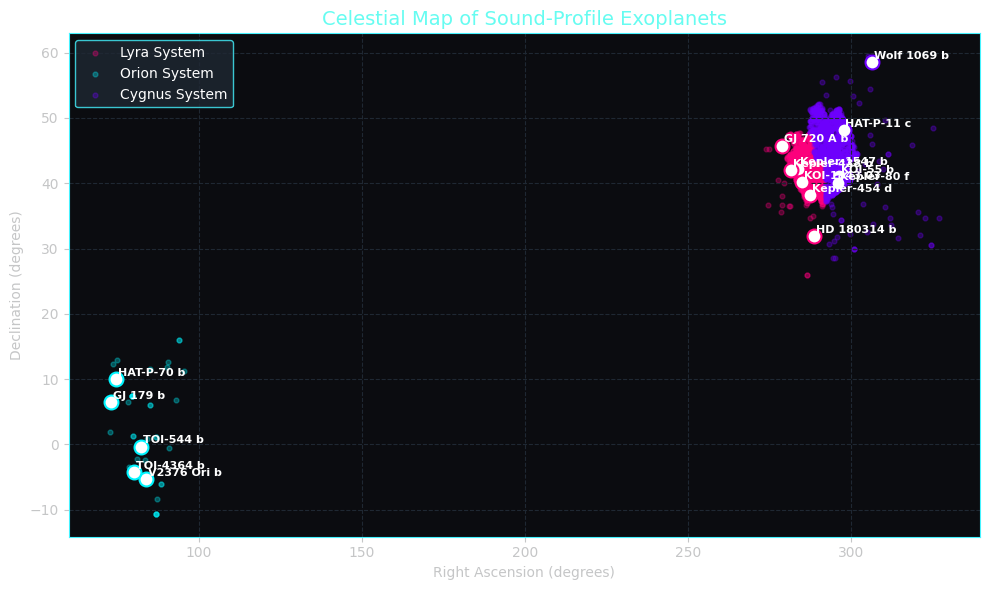

In [40]:
# CELL 12 – Sky Coordinate Mapping Plot
plt.figure(figsize=(10, 6))
ax = plt.subplot(1, 1, 1, facecolor='#0B0C10')

# Filter background planets from chosen constellations
colors = ["#ff007f", "#00f5ff", "#7000ff"]

for i, c in enumerate(CONSTELLATIONS):
    # Gather all background planets of this constellation
    bg_subset = df_planets[df_planets["constellation"].str.lower() == c.lower()]
    if bg_subset.empty:
        continue

    plt.scatter(
        bg_subset["ra"],
        bg_subset["dec"],
        color=colors[i % len(colors)],
        alpha=0.3,
        s=12,
        label=f"{c} System"
    )

    # Superimpose and highlight featured extremes
    featured = featured_planets.get(c, [])
    for f_p in featured:
        plt.scatter(
            f_p["ra"],
            f_p["dec"],
            color="#ffffff",
            edgecolors=colors[i % len(colors)],
            s=100,
            linewidth=1.5,
            zorder=5
        )
        plt.text(
            f_p["ra"] + 0.5,
            f_p["dec"] + 0.5,
            f_p["pl_name"],
            color="#ffffff",
            fontsize=8,
            fontweight='bold',
            zorder=6
        )

plt.title("Celestial Map of Sound-Profile Exoplanets", color='#66FCF1', fontsize=14)
plt.xlabel("Right Ascension (degrees)", color='#C5C6C7')
plt.ylabel("Declination (degrees)", color='#C5C6C7')

# Adjust axis colors
ax.tick_params(colors='#C5C6C7')
for spine in ax.spines.values():
    spine.set_color('#45F3FF')

plt.legend(facecolor='#1F2833', edgecolor='#45F3FF', labelcolor='#ffffff')
plt.grid(color='#1F2833', linestyle='--')
plt.tight_layout()
plt.show()